In [36]:
# Bibliotecas utilizadas

import numpy as np
import matplotlib.pyplot as plt

# Constantes utilizadas

pi = np.pi

# Representação matricial da DFT #

A DFT e a IDFT, em suas definições, são:

$$X(k)=\sum\limits_{n=0}^{N-1}x(n){W_N}^{kn}\,,\,n=0,1,...,N-1$$
$$x(n)=\begin{cases}
\frac{1}{N}\sum\limits_{k=0}^{N-1}X(k){W_N}^{-kn}\,,\,n=0,1,...,N-1 \\
0\hspace{2.7cm},\,\text{caso contrário}
\end{cases}
\,.
$$

Onde

$$W_N=e^{-j\frac{2\pi}{N}}\,.$$

Vetorizando $x(n)$ e $X(k)$, é possível representar a DFT e a IDFT de forma matricial: 

$$\begin{bmatrix}
X(0) \\
X(1) \\
X(2) \\
\vdots \\
X(N-1)
\end{bmatrix} =
\begin{bmatrix}
1 & 1 & 1 & \cdots & 1 \\
1 & {W_N}^1 & {W_N}^2 & \cdots & {W_N}^{N-1} \\
1 & {W_N}^2 & {W_N}^4 & \cdots & {W_N}^{2(N-1)} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & {W_N}^{N-1} & {W_N}^{2(N-1)} & \cdots & {W_N}^{(N-1)^2}
\end{bmatrix}
\begin{bmatrix}
x(0) \\
x(1) \\
x(2) \\
\vdots \\
x(N-1)
\end{bmatrix}
$$



$$\begin{bmatrix}
x(0) \\
x(1) \\
x(2) \\
\vdots \\
x(N-1)
\end{bmatrix} = \frac{1}{N}
\begin{bmatrix}
1 & 1 & 1 & \cdots & 1 \\
1 & {W_N}^{-1} & {W_N}^{-2} & \cdots & {W_N}^{-(N-1)} \\
1 & {W_N}^{-2} & {W_N}^{-4} & \cdots & {W_N}^{-2(N-1)} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & {W_N}^{-(N-1)} & {W_N}^{-2(N-1)} & \cdots & {W_N}^{-(N-1)^2}
\end{bmatrix}
\begin{bmatrix}
X(0) \\
X(1) \\
X(2) \\
\vdots \\
X(N-1)
\end{bmatrix}
$$

In [37]:
def W(N):
    return np.exp(-2j*pi/N)

def DFT(x,N):
    x_copy = x.copy()
    L = len(x_copy)
    if N < L:
        raise Exception('N deve ser maior que o número de pontos de x(n)')
    if N > L:
        x_copy = np.append(x_copy, [0]*(N-L))

    WN = W(N)
    i, j = np.indices((N,N))
    W_matrix = WN**(i*j)

    X = W_matrix @ x_copy
    return X

def IDFT(X):
    X_copy = X.copy()
    N = len(X_copy)

    WN = W(N)
    i, j = np.indices((N,N))
    W_m1_matrix = WN**(-i*j)

    x = (W_m1_matrix @ X_copy)/N
    return x

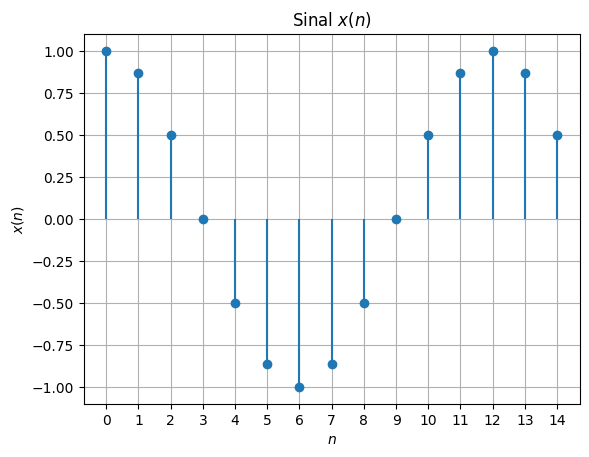

In [38]:
L = 15

A = 1

n_array = np.arange(0,L,1)
#x = A*np.ones(len(n_array))
x = A*np.cos(pi*n_array/6)

plt.stem(n_array, x, basefmt=' ')
plt.grid(True)
if L < 20:
    plt.xticks(n_array)
plt.title(r'Sinal $x(n)$')
plt.xlabel(r'$n$')
plt.ylabel(r'$x(n)$')
plt.show()

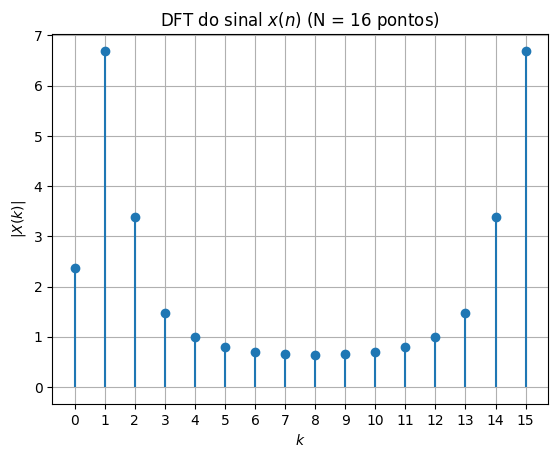

In [39]:
N = 16

k_array = np.arange(0,N,1)
X = DFT(x, N)

plt.stem(k_array, np.abs(X), basefmt=' ')
plt.grid(True)
if N < 20:
    plt.xticks(k_array)
plt.title(r'DFT do sinal $x(n)$ (N = %d pontos)' %N)
plt.xlabel(r'$k$')
plt.ylabel(r'$|X(k)|$')
plt.show()

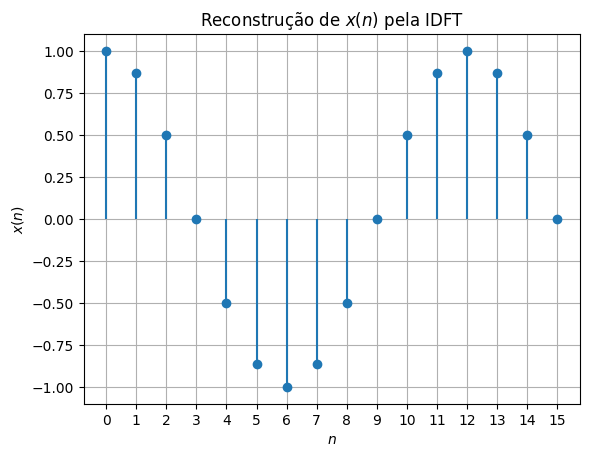

In [40]:
x_IDFT = np.real(IDFT(X))

plt.stem(k_array, x_IDFT, basefmt=' ')
plt.grid(True)
if N < 20:
    plt.xticks(k_array)
plt.title(r'Reconstrução de $x(n)$ pela IDFT')
plt.xlabel(r'$n$')
plt.ylabel(r'$x(n)$')
plt.show()